In [1]:
# %pip install pandas
# %pip install numpy
# %pip install matplotlib
# %pip install seaborn
# %pip install warnings
# %pip install yaml

In [20]:
%pip install spicy

   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 1.8/36.7 MB 14.3 MB/s eta 0:00:03
   ---------- ----------------------------- 10.0/36.7 MB 29.5 MB/s eta 0:00:01
   ------------------- -------------------- 17.8/36.7 MB 32.1 MB/s eta 0:00:01
   --------------------------- ------------ 25.2/36.7 MB 33.9 MB/s eta 0:00:01
   ----------------------------------- ---- 32.8/36.7 MB 34.7 MB/s eta 0:00:01
   ---------------------------------------- 36.7/36.7 MB 31.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#librerias basicas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.options.display.max_columns=None
import yaml

pd.options.display.max_rows=None

In [4]:
import importlib

In [7]:
from pathlib import Path

In [10]:
pwd

'c:\\Users\\Alberto\\Desktop\\Ing. Estadística\\cursos importantes\\Ciencia de datos (DENIS)\\S3\\exp_proyecto_prueba\\notebooks'

In [22]:
#nombre de proyecto
nombre_exp='exp_proyecto_prueba' #colocar nombre de la carepta que contiene el proyecto

In [23]:
##ruta actual
ruta_actual = Path.cwd()
#Buscar la carpeta del proyecto en la ruta actual
partes = ruta_actual.parts
ruta_raiz = ruta_actual
for i, p in enumerate(partes):
    if p == nombre_exp:
        ruta_raiz = Path(*partes[:i + 1])
        break
ruta_raiz = str(ruta_raiz)

In [19]:
ruta_raiz

'c:\\Users\\Alberto\\Desktop\\Ing. Estadística\\cursos importantes\\Ciencia de datos (DENIS)\\S3\\exp_proyecto_prueba\\notebooks'

In [24]:
#cargando metadata archivo configuracion .yaml
config_path = Path(ruta_raiz) / 'config' / 'model' / 'archivo_config.yaml'
with open(config_path, 'r', encoding='utf-8') as file:
    config = yaml.safe_load(file)


In [25]:
###permite cargar modulos scripts.py
import sys
import os
dir=os.path.abspath(config['settings']['ruta_src'])
if dir not in sys.path:
    sys.path.append(dir)

In [12]:
from prep_EDA import validar_numerico

In [15]:
#recarga modulo cargado en memoria para no reiniciar kernel
importlib.reload(sys.modules['prep_detect_asimetria'])

KeyError: 'prep_detect_asimetria'

In [26]:
#rutas data
path_data_pro=config['settings']['ruta_data_pro']
path_raiz=config['settings']['ruta_raiz']
path_data_raw=config['settings']['ruta_data_raw']
path_data_final=config['settings']['ruta_data_final']
path_models=config['settings']['ruta_models']

In [27]:
df = pd.read_csv(path_data_raw + "/base_churn_telcov2.csv")

In [28]:
df.head()

,PERIODO,CUSTOMER_ID,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL,CONSUMO_GB,RECLAMOS_3M,RECLAMOS_12M,TICKETS_TECNICOS,CAIDAS_SERVICIO,DIAS_MORA,PAGOS_ATRASADOS_12M,SATISFACCION,VISITAS_WEB,VISITAS_APP,CAMPANIAS_RECIBIDAS,CAMPANIAS_RESPONDIDAS,VELOCIDAD_REAL,USO_STREAMING,USO_GAMING,N_PRODUCTOS,TENURE_ULTIMO_UPGRADE,INGRESO_HOGAR,COMPETENCIA_ZONA,SCORE_RIESGO,CONTACTOS_CALLCENTER,INTERACCIONES_DIGITALES,VELOCIDAD_VARIABILIDAD,DESCUENTO_PCT,USO_NOCTURNO,USO_FIN_SEMANA,SEGMENTO,TECNOLOGIA,REGION,SEXO,CANAL_VENTA,CHURN_VOLUNTARIO,DISTRITO,FLAG_PREMIUM_FALSO,RENTA_MENSUAL_2,FLAG_RETENCION_EXITOSA,YEAR,FLAG_EMPRESA,FLAG_CASI_CONSTANTE,RENTA_MENSUAL_3,ID_CONTRATO,RECLAMOS_RED_SOCIAL
0,2023-01-01,CUST_000001,113,71.0,50,4.104834,367.997453,2,3,1,0,0,2,7.527282,21,11,7,1,41.457487,53,52,2,48,3876.011607,2,0.253798,3,7,4.408812,36.683128,99.827743,78.052058,Masivo,Fibra,Lima,M,Call Center,0,DIST_388,1,9.349668,0,2023,1,1,5.200272,CONT_0,0.302734
1,2023-02-01,CUST_000001,114,71.0,50,1.757508,323.404792,2,6,1,0,3,3,8.790275,14,11,3,2,150.000000,96,5,2,40,3619.095364,2,0.591510,1,7,24.756448,5.708874,30.954199,56.910698,Masivo,Fibra,Lima,M,Call Center,0,DIST_233,1,-1.562136,0,2023,1,1,0.909783,CONT_1,1.886790
2,2023-03-01,CUST_000001,115,71.0,50,6.830930,385.972005,1,4,1,0,5,1,6.531012,11,6,3,2,53.427387,34,37,2,34,NaN,2,0.601026,3,6,27.236718,14.527568,28.715226,50.073491,Masivo,Fibra,Lima,M,Call Center,0,DIST_121,1,9.173178,1,2023,1,1,3.388333,CONT_2,1.073655
3,2023-04-01,CUST_000001,116,71.0,50,-11.446290,363.553714,3,5,1,6,2,2,7.767388,14,15,1,1,40.719442,53,89,2,16,3690.253173,2,0.958565,3,6,0.767369,31.868347,60.014048,71.092964,Masivo,Fibra,Lima,M,Call Center,0,DIST_203,1,-15.310123,0,2023,1,1,-9.044153,CONT_3,2.436723
4,2023-05-01,CUST_000001,117,71.0,50,-11.588707,390.446332,1,3,0,1,4,1,6.245754,11,15,4,4,NaN,74,84,2,29,NaN,2,0.764246,1,7,9.918989,3.612742,56.265412,47.904073,Masivo,Fibra,Lima,M,Call Center,0,DIST_87,1,-8.563236,0,2023,1,1,-11.721606,CONT_4,0.047751


In [29]:
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp

import warnings
warnings.filterwarnings("ignore")

TARGET = "CHURN_VOLUNTARIO"
ID_COL = "CUSTOMER_ID"
DATE_COL = "PERIODO"

df[DATE_COL] = pd.to_datetime(df[DATE_COL])

num_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

cat_cols = df.select_dtypes(
    include=["object","category"]
).columns.tolist()

# excluir target y id

num_cols = [
    c for c in num_cols
    if c != TARGET
]

cat_cols = [
    c for c in cat_cols
    if c != ID_COL
]

In [30]:
#1. Cantidad de variables y filas
print("Filas :", len(df))
print("Columnas :", len(df.columns))

print("\nVariables Numéricas")
print(len(num_cols))

print("\nVariables Categóricas")
print(len(cat_cols))

Filas : 23626
Columnas : 48

Variables Numéricas
38

Variables Categóricas
7


In [23]:
#2. Análisis de nulos
nulos = pd.DataFrame({

    "feature":df.columns,

    "nulos":
        df.isnull().sum(),

    "pct_nulos":
        round(
            100*df.isnull().mean(),
            2
        )

})

nulos.sort_values(
    "pct_nulos",
    ascending=False
)

,feature,nulos,pct_nulos
VELOCIDAD_REAL,VELOCIDAD_REAL,9392,39.75
INGRESO_HOGAR,INGRESO_HOGAR,4522,19.14
EDAD_CLIENTE,EDAD_CLIENTE,2313,9.79
SATISFACCION,SATISFACCION,60,0.25
VELOCIDAD_PLAN,VELOCIDAD_PLAN,0,0.00
RENTA_MENSUAL,RENTA_MENSUAL,0,0.00
CUSTOMER_ID,CUSTOMER_ID,0,0.00
PERIODO,PERIODO,0,0.00
RECLAMOS_3M,RECLAMOS_3M,0,0.00
RECLAMOS_12M,RECLAMOS_12M,0,0.00


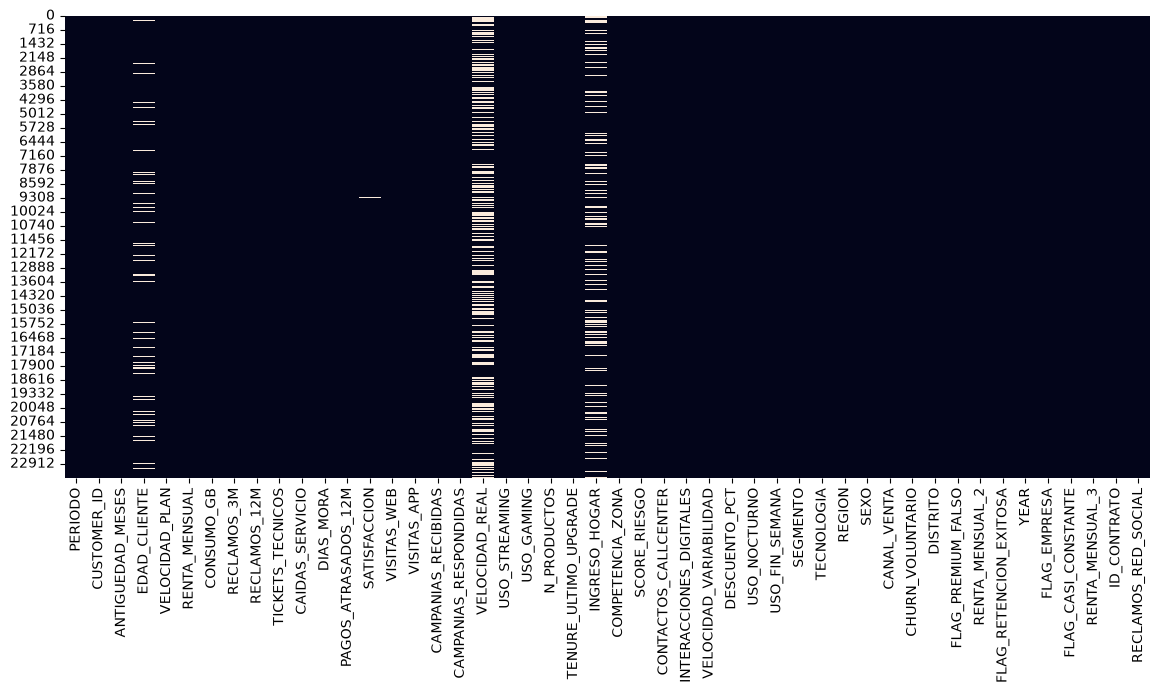

In [24]:
#Heatmap de nulos
plt.figure(figsize=(14,6))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.show()

In [25]:
#Detección MCAR / MAR / MNAR
#Ejemplo para INGRESO_HOGAR.
missing_flag = (
    df["INGRESO_HOGAR"]
    .isnull()
    .astype(int)
)

In [26]:
#Cruzar contra variables.
for col in num_cols[:10]:

    corr = np.corrcoef(
        missing_flag,
        df[col].fillna(
            df[col].median()
        )
    )[0,1]

    print(
        col,
        round(corr,3)
    )

ANTIGUEDAD_MESES 0.007
EDAD_CLIENTE -0.018
VELOCIDAD_PLAN -0.002
RENTA_MENSUAL -0.003
CONSUMO_GB 0.007
RECLAMOS_3M 0.002
RECLAMOS_12M 0.005
TICKETS_TECNICOS -0.004
CAIDAS_SERVICIO 0.004
DIAS_MORA 0.006


## Creación de ventanas

In [31]:
df1 = pd.read_csv(path_data_raw + "/dataset_churn_ventanas.csv")

In [ ]:
# A esto se le llama ABT 
# siempre se hace preprocesamiento de datos en el train para evitar OVERFITTING
df1.head(5)

,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,TICKETS_TECNICOS_6M,CAIDAS_SERVICIO_6M,DIAS_MORA_6M,PAGOS_ATRASADOS_12M_6M,SATISFACCION_6M,VISITAS_WEB_6M,VISITAS_APP_6M,CAMPANIAS_RECIBIDAS_6M,CAMPANIAS_RESPONDIDAS_6M,VELOCIDAD_REAL_6M,USO_STREAMING_6M,USO_GAMING_6M,N_PRODUCTOS_6M,TENURE_ULTIMO_UPGRADE_6M,INGRESO_HOGAR_6M,COMPETENCIA_ZONA_6M,SCORE_RIESGO_6M,CONTACTOS_CALLCENTER_6M,INTERACCIONES_DIGITALES_6M,VELOCIDAD_VARIABILIDAD_6M,DESCUENTO_PCT_6M,USO_NOCTURNO_6M,USO_FIN_SEMANA_6M,FLAG_PREMIUM_FALSO_6M,RENTA_MENSUAL_2_6M,FLAG_EMPRESA_6M,FLAG_CASI_CONSTANTE_6M,RENTA_MENSUAL_3_6M,RECLAMOS_RED_SOCIAL_6M,INTERACCIONES_DIGITALES_SUM_6M,RECLAMOS_RED_SOCIAL_SUM_6M,DIAS_MORA_SUM_6M,RECLAMOS_3M_SUM_6M,CAMPANIAS_RESPONDIDAS_SUM_6M,CONTACTOS_CALLCENTER_SUM_6M,N_PRODUCTOS_SUM_6M,VISITAS_APP_SUM_6M,VISITAS_WEB_SUM_6M,PAGOS_ATRASADOS_12M_SUM_6M,CAMPANIAS_RECIBIDAS_SUM_6M,RECLAMOS_12M_SUM_6M,TICKETS_TECNICOS_SUM_6M,CAIDAS_SERVICIO_SUM_6M,RENTA_MENSUAL_3M,CONSUMO_GB_3M,RECLAMOS_3M_3M,RECLAMOS_12M_3M,TICKETS_TECNICOS_3M,CAIDAS_SERVICIO_3M,DIAS_MORA_3M,PAGOS_ATRASADOS_12M_3M,SATISFACCION_3M,VISITAS_WEB_3M,VISITAS_APP_3M,CAMPANIAS_RECIBIDAS_3M,CAMPANIAS_RESPONDIDAS_3M,VELOCIDAD_REAL_3M,USO_STREAMING_3M,USO_GAMING_3M,N_PRODUCTOS_3M,TENURE_ULTIMO_UPGRADE_3M,INGRESO_HOGAR_3M,COMPETENCIA_ZONA_3M,SCORE_RIESGO_3M,CONTACTOS_CALLCENTER_3M,INTERACCIONES_DIGITALES_3M,VELOCIDAD_VARIABILIDAD_3M,DESCUENTO_PCT_3M,USO_NOCTURNO_3M,USO_FIN_SEMANA_3M,FLAG_PREMIUM_FALSO_3M,RENTA_MENSUAL_2_3M,FLAG_EMPRESA_3M,FLAG_CASI_CONSTANTE_3M,RENTA_MENSUAL_3_3M,RECLAMOS_RED_SOCIAL_3M,INTERACCIONES_DIGITALES_SUM_3M,RECLAMOS_RED_SOCIAL_SUM_3M,DIAS_MORA_SUM_3M,RECLAMOS_3M_SUM_3M,CAMPANIAS_RESPONDIDAS_SUM_3M,CONTACTOS_CALLCENTER_SUM_3M,N_PRODUCTOS_SUM_3M,VISITAS_APP_SUM_3M,VISITAS_WEB_SUM_3M,PAGOS_ATRASADOS_12M_SUM_3M,CAMPANIAS_RECIBIDAS_SUM_3M,RECLAMOS_12M_SUM_3M,TICKETS_TECNICOS_SUM_3M,CAIDAS_SERVICIO_SUM_3M,RENTA_MENSUAL_UM,CONSUMO_GB_UM,RECLAMOS_3M_UM,RECLAMOS_12M_UM,TICKETS_TECNICOS_UM,CAIDAS_SERVICIO_UM,DIAS_MORA_UM,PAGOS_ATRASADOS_12M_UM,SATISFACCION_UM,VISITAS_WEB_UM,VISITAS_APP_UM,CAMPANIAS_RECIBIDAS_UM,CAMPANIAS_RESPONDIDAS_UM,VELOCIDAD_REAL_UM,USO_STREAMING_UM,USO_GAMING_UM,N_PRODUCTOS_UM,TENURE_ULTIMO_UPGRADE_UM,INGRESO_HOGAR_UM,COMPETENCIA_ZONA_UM,SCORE_RIESGO_UM,CONTACTOS_CALLCENTER_UM,INTERACCIONES_DIGITALES_UM,VELOCIDAD_VARIABILIDAD_UM,DESCUENTO_PCT_UM,USO_NOCTURNO_UM,USO_FIN_SEMANA_UM,FLAG_PREMIUM_FALSO_UM,RENTA_MENSUAL_2_UM,FLAG_EMPRESA_UM,FLAG_CASI_CONSTANTE_UM,RENTA_MENSUAL_3_UM,RECLAMOS_RED_SOCIAL_UM,SEGMENTO_MODE_6M,SEGMENTO_MODE_3M,SEGMENTO_UM,TECNOLOGIA_MODE_6M,TECNOLOGIA_MODE_3M,TECNOLOGIA_UM,REGION_MODE_6M,REGION_MODE_3M,REGION_UM,SEXO_MODE_6M,SEXO_MODE_3M,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET
0,CUST_000001,VENTANA1,0,129.0,72.0,50.0,6.479856,384.699198,0.833333,3.333333,1.166667,1.666667,1.833333,1.833333,8.710954,15.000000,13.500000,3.166667,1.833333,45.068107,37.833333,52.500000,2.0,20.666667,3691.652991,2.0,0.607967,1.000000,9.666667,11.139647,25.245184,57.613889,52.874262,1.0,5.711413,1.0,1.0,6.840057,0.709838,58.0,4.259030,11.0,5.0,11.0,6.0,12.0,81.0,90.0,11.0,19.0,20.0,7.0,10.0,6.715143,389.947847,1.000000,3.333333,1.000000,2.000000,1.333333,2.333333,8.198737,16.000000,14.333333,2.666667,2.666667,43.446478,50.000000,31.666667,2.0,29.000000,3893.858731,2.0,0.795065,0.666667,7.666667,15.601024,24.523643,29.979000,40.526860,1.0,5.910491,1.0,1.0,6.552893,1.049271,23.0,3.147813,4.0,3.0,8.0,2.0,6.0,43.0,48.0,7.0,8.0,10.0,3.0,6.0,9.463746,378.551997,2.0,5.0,1.0,2.0,3.0,4.0,8.234211,14.0,19.0,4.0,4.0,44.178550,43.0,21.0,2.0,30.0,NaN,2.0,0.854268,0.0,10.0,25.043955,30.472210,32.909588,53.395655,1.0,7.537784,1.0,1.0,10.661309,1.180396,Masivo,Masivo,Masivo,Fibra,Fibra,Fibra,Lima,Lima,Lima,M,M,M,Call Center,Call Center,Call Center,DIST_124,DI

In [36]:
num_cols = df1.select_dtypes(include=np.number).columns.tolist()

cat_cols = df1.select_dtypes(include=["object","category"]).columns.tolist()

# excluir target y id

num_cols = [c for c in num_cols if c != TARGET]

cat_cols = [c for c in cat_cols if c != ID_COL]

In [39]:
len(num_cols)

131

In [40]:
len(cat_cols)

22

### Análisis de Nulos

In [ ]:
#2. Análisis de nulos
nulos = pd.DataFrame({
    "feature":df1.columns,
    "nulos": df1.isnull().sum(),
    "pct_nulos":round(df1.isnull().mean(),2)})
nulos.sort_values("pct_nulos",ascending=False)


,feature,nulos,pct_nulos
VELOCIDAD_REAL_UM,VELOCIDAD_REAL_UM,1050,0.39
INGRESO_HOGAR_UM,INGRESO_HOGAR_UM,529,0.20
VELOCIDAD_REAL_3M,VELOCIDAD_REAL_3M,151,0.06
INGRESO_HOGAR_3M,INGRESO_HOGAR_3M,73,0.03
INGRESO_HOGAR_6M,INGRESO_HOGAR_6M,37,0.01
VELOCIDAD_PLAN,VELOCIDAD_PLAN,0,0.00
TARGET_CHURN,TARGET_CHURN,0,0.00
ANTIGUEDAD_MESES,ANTIGUEDAD_MESES,0,0.00
EDAD_CLIENTE,EDAD_CLIENTE,0,0.00
CUSTOMER_ID,CUSTOMER_ID,0,0.00


In [44]:
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.multitest import multipletests

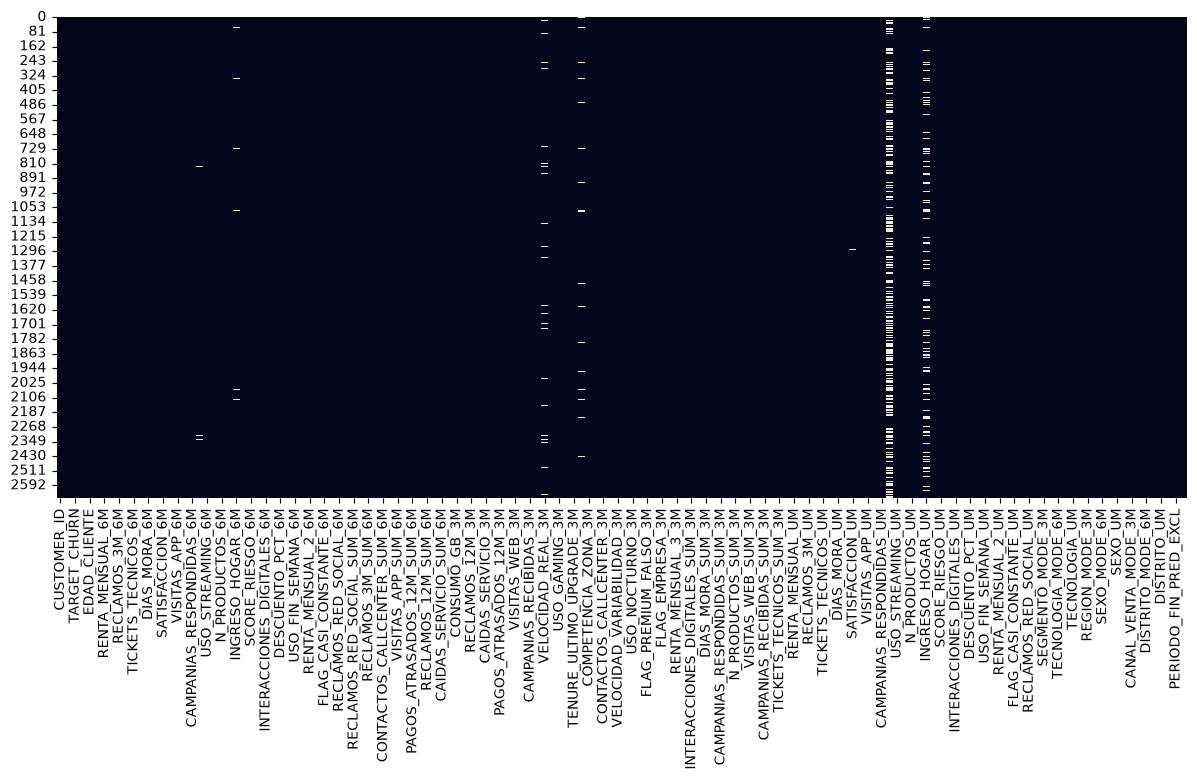

In [43]:
#Heatmap de nulos
plt.figure(figsize=(14,6))
sns.heatmap(df1.isnull(),cbar=False)
plt.show()

In [ ]:
#H0: Los datos faltan completamente al azar (MCAR)
#    las medias de cada variable NO cambian entre grupos con y sin NA 

#(H1): Los datos NO faltan al azar
#      las medias SÍ cambian según el patrón de NA

### Detección de anomalías

Diferencia entre outlier y una anomalía; el outlier se puede hallar con estadística. 
dato anómalo es un patrón (por eso se puede predecir); una anomalía puede ser un outlier, pero un outlier no puede ser una anomalía. 

Anomalía local y externa

* Local: Un dato que parece normal si miras todo el dataset, pero es raro comparado con sus vecinos más cercanos (un subgrupo o clúster específico).

* Externa o Exógena: Un dato que se aleja muchísimo de todo el conjunto de datos (no se hace con isolation forest, aquí ayuda el DBSCAN--> usualmente lo detecta como -1)